# Selección de pesos para la fusión de DART y CRNN

Se cargan los dos modelos entrenados con las mismas 80 personas. Cada modelo predice las etapas de las 39 noches de las 20 personas reservadas. Se comparan 101 mezclas geométricas, desde 0 % hasta 100 % de DART en incrementos de un punto. La referencia es 70 % DART y 30 % CRNN.

La selección maximiza el F1 macro de las cinco etapas en las 20 personas. En caso de empate se prefiere la mezcla más cercana a la referencia y después la de menor porcentaje de DART. Estos resultados describen la selección en esta partición.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
from time import perf_counter
from uuid import uuid4

os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '5')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.special import softmax
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data.dvc').is_file())
sys.path.insert(0, str(ROOT/'packages/sleep-staging/src'))
from sleep_staging.datasets import discover_sleep_cassette_records, discover_sleep_telemetry_records, read_epoch_labels

DATA = ROOT/'data'
VERSION = 'dart_666_crnn_27_20261119_191036'
salida = DATA/'experimentos/dart_crnn_mixto'/VERSION
directorio = DATA/'models/dart_crnn_mixto'/'evaluacion_80_20'
inicio = perf_counter()

def sha256(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as f:
        for bloque in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

seleccion = json.loads((salida/'hiperparametros.json').read_text('utf8'))
from sleep_staging.inference.mixed_bundle import read_training_manifest
ficha = read_training_manifest(directorio/'manifest.json', salida)
contrato = ficha['contrato']
assert hashlib.sha256(json.dumps(contrato, sort_keys=True, ensure_ascii=False).encode('utf8')).hexdigest() == ficha['firma']
assert contrato['parametros_dart']['n_estimators'] == seleccion['iteraciones_dart']
assert contrato['epocas_crnn'] == seleccion['epocas_crnn']
assert (len(contrato['personas_entrenamiento']), len(contrato['registros_entrenamiento']),
        contrato['segmentos_entrenamiento']) == (80, 158, 365283)
pesos = {rama: directorio/info['nombre'] for rama, info in ficha['archivos'].items()}
for rama, ruta in pesos.items():
    assert sha256(ruta) == ficha['archivos'][rama]['sha256'], rama
dart = lgb.Booster(model_file=str(pesos['dart']))
crnn = tf.keras.models.load_model(pesos['crnn'], compile=False)
CLASES = np.array(contrato['clases'])
DESFASES = tuple(contrato['desfases'])
print(f"Pesos cargados: DART de {dart.current_iteration()} iteraciones y CRNN de {contrato['epocas_crnn']} épocas.")

Pesos cargados: DART de 666 iteraciones y CRNN de 27 épocas.


## Predicciones sobre el grupo reservado

Las entradas tabulares y espectrales se recuperan de las cachés por la huella de cada señal. Se conservan las noches por separado para aplicar los tres desfases de la CRNN. Las predicciones se comparan con las etiquetas del hipnograma en las épocas de 30 segundos con clasificación válida.

In [2]:
registros = {'Telemetry': discover_sleep_telemetry_records(DATA/'sleep-telemetry'),
             'Cassette': discover_sleep_cassette_records(DATA/'sleep-cassette')}
personas = pd.DataFrame([(cohorte, r.subject_id) for cohorte, lista in registros.items() for r in lista],
                        columns=['cohorte', 'subject_id']).drop_duplicates().sort_values(['cohorte','subject_id'])
it, iv = next(StratifiedKFold(5, shuffle=True, random_state=42).split(personas, personas.cohorte))
ids_prueba = set(personas.iloc[iv].subject_id)
assert set(personas.iloc[it].subject_id) == set(contrato['personas_entrenamiento'])
assert len(ids_prueba) == 20 and ids_prueba.isdisjoint(contrato['personas_entrenamiento'])
cache_dart = {}
for ruta in (DATA/'processed/dart_inferencia').glob('*/preprocesamiento.json'):
    receta = json.loads(ruta.read_text('utf8'))
    for cohorte, perfil in contrato['preprocesamiento_dart'].items():
        if receta['perfil'] == perfil and receta['paquete'] == contrato['paquete']:
            if cohorte in cache_dart:
                raise ValueError(f'Hay más de una caché DART compatible para {cohorte}.')
            cache_dart[cohorte] = ruta.parent
assert set(cache_dart) == set(registros)
cache_crnn = DATA/'processed/crnn_espectral'/seleccion['receta_espectral']

def probabilidad_crnn(red, espectro):
    vistas = []
    for d in DESFASES:
        pad = [(d, -(len(espectro)+d) % 15), (0,0), (0,0)]
        bloques = np.pad(espectro, pad).reshape(-1, 15, 6, 96)
        pred = red.predict(bloques, batch_size=128, verbose=0).reshape(-1,len(CLASES))
        vistas.append(pred[d:d+len(espectro)].astype('float64'))
    return softmax(np.log(np.maximum(vistas, 1e-10)).mean(axis=0), axis=1)

tablas, redes, indices = [], [], []
for cohorte, lista in registros.items():
    for r in lista:
        if r.subject_id not in ids_prueba:
            continue
        huella = sha256(r.psg_path)
        nombre = f'{r.psg_path.stem}-{huella}'
        tab = pd.read_parquet(cache_dart[cohorte]/(nombre+'.parquet'))
        espectro = np.load(cache_crnn/(nombre+'.npy'), mmap_mode='r', allow_pickle=False)
        assert len(espectro) == len(tab) and np.array_equal(tab.epoch_index, np.arange(len(tab)))
        etapas = read_epoch_labels(r.hypnogram_path, len(tab))
        validas = np.isin(etapas, CLASES)
        x = tab.loc[validas].reindex(columns=contrato['columnas_dart']).astype('float32')
        tablas.append(dart.predict(x, num_threads=4))
        redes.append(probabilidad_crnn(crnn, espectro)[validas])
        indices.append(pd.DataFrame(dict(cohorte=cohorte, persona=r.subject_id, registro=r.record_id,
                                         epoca=tab.epoch_index.to_numpy()[validas], etapa=etapas[validas])))
p_dart, p_crnn = np.concatenate(tablas), np.concatenate(redes)
filas = pd.concat(indices, ignore_index=True)
assert (filas.persona.nunique(), filas.registro.nunique(), len(filas)) == (20,39,92369)
assert p_dart.shape == p_crnn.shape == (92369,5)
for p in (p_dart, p_crnn):
    np.testing.assert_allclose(p.sum(axis=1), 1., atol=1e-6)
display(filas.groupby('cohorte').agg(personas=('persona','nunique'), noches=('registro','nunique'), segmentos=('etapa','size')))

,personas,noches,segmentos
cohorte,,,
Cassette,16,31,84492
Telemetry,4,8,7877


## Barrido de proporciones

Cada proporción se aplica a las mismas predicciones. Los porcentajes de ambos modelos suman 100. Se miden F1 macro, exactitud y kappa de Cohen.

,crnn_pct,f1_macro,exactitud,kappa
dart_pct,,,,
0,100,0.79338,0.91270,0.84445
59,41,0.81456,0.91950,0.85632
70,30,0.81230,0.91767,0.85305
100,0,0.79361,0.90591,0.83193


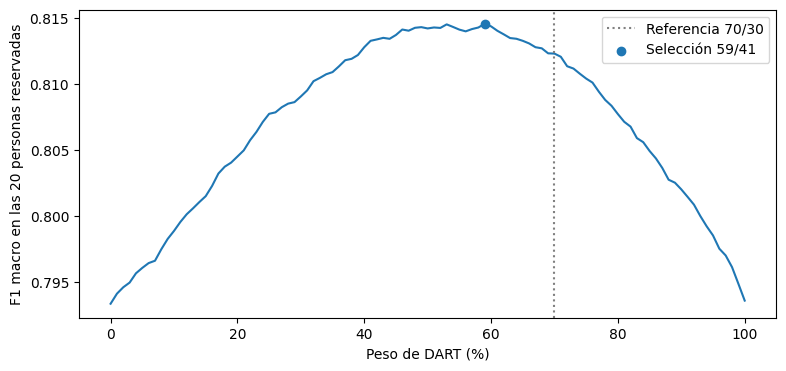

f1_macro  exactitud    kappa
dart_pct crnn_pct cohorte                                
59       41       Cassette    0.81164    0.92761  0.85702
                  Telemetry   0.79179    0.83242  0.76221
70       30       Cassette    0.80903    0.92570  0.85316
                  Telemetry   0.78919    0.83153  0.76189

In [3]:
log_dart = np.log(np.maximum(p_dart, 1e-7))
log_crnn = np.log(np.maximum(p_crnn, 1e-7))
y = pd.Categorical(filas.etapa, categories=CLASES).codes
etiquetas = np.arange(len(CLASES))

def aplicar(pct):
    return ((pct/100)*log_dart + ((100-pct)/100)*log_crnn).argmax(axis=1)

def metricas(real, pred):
    return dict(f1_macro=float(f1_score(real, pred, labels=etiquetas, average='macro', zero_division=0)),
                exactitud=float(accuracy_score(real,pred)), kappa=float(cohen_kappa_score(real,pred)))

curva = pd.DataFrame([dict(dart_pct=pct, crnn_pct=100-pct, **metricas(y, aplicar(pct))) for pct in range(101)])
orden = curva.assign(distancia=(curva.dart_pct-70).abs()).sort_values(
    ['f1_macro','distancia','dart_pct'], ascending=[False,True,True])
mejor = int(orden.iloc[0].dart_pct)
tabla = curva.set_index('dart_pct')
display(tabla.loc[sorted({0, 70, mejor, 100})].round(5))
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(curva.dart_pct, curva.f1_macro)
ax.axvline(70, color='grey', linestyle=':', label='Referencia 70/30')
ax.scatter([mejor], [tabla.at[mejor,'f1_macro']], label=f'Selección {mejor}/{100-mejor}', zorder=3)
ax.set(xlabel='Peso de DART (%)', ylabel='F1 macro en las 20 personas reservadas')
ax.legend()
plt.show()
por_cohorte = []
for pct in sorted({70, mejor}):
    pred = aplicar(pct)
    for cohorte, grupo in filas.groupby('cohorte'):
        idx = grupo.index
        por_cohorte.append(dict(dart_pct=pct, crnn_pct=100-pct, cohorte=cohorte, **metricas(y[idx],pred[idx])))
display(pd.DataFrame(por_cohorte).set_index(['dart_pct','crnn_pct','cohorte']).round(5))

## Resultados reutilizables

La tabla completa, la comparación por cohorte y las probabilidades de cada rama se guardan con la selección. El informe registra las huellas de ambos modelos y las personas reservadas para rastrear la mezcla que se utilizará en el ajuste final.

In [4]:
curva.to_csv(salida/'mezclas.csv', index=False)
pd.DataFrame(por_cohorte).to_csv(salida/'mezclas_por_cohorte.csv', index=False)
np.savez_compressed(salida/'predicciones_80_20.npz', dart=p_dart, crnn=p_crnn, clase_real=y,
                    clases=CLASES, registro=filas.registro.to_numpy(dtype=str), epoca=filas.epoca.to_numpy())
informe = dict(version=VERSION, iteraciones_dart=seleccion['iteraciones_dart'], epocas_crnn=seleccion['epocas_crnn'],
               porcentaje_dart=mejor, porcentaje_crnn=100-mejor, criterio='F1 macro; empate por cercanía a 70/30 y menor % de DART',
               referencia_70_30=metricas(y,aplicar(70)), seleccion=metricas(y,aplicar(mejor)),
               aumento_pp=float(100*(tabla.at[mejor,'f1_macro']-tabla.at[70,'f1_macro'])),
               dart_solo=metricas(y,aplicar(100)), crnn_sola=metricas(y,aplicar(0)),
               personas_prueba=sorted(ids_prueba), noches_prueba=39, segmentos_prueba=len(filas),
               sha256_pesos={k:v['sha256'] for k,v in ficha['archivos'].items()},
               segundos=perf_counter()-inicio)
temporal = salida/(uuid4().hex+'.tmp')
temporal.write_text(json.dumps(informe,ensure_ascii=False,indent=2),encoding='utf8')
temporal.replace(salida/'fusion.json')
print(f"Mezcla elegida: {mejor}% DART y {100-mejor}% CRNN. Diferencia con 70/30: {informe['aumento_pp']:+.3f} puntos de F1 macro.")

Mezcla elegida: 59% DART y 41% CRNN. Diferencia con 70/30: +0.226 puntos de F1 macro.
